In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib")


PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG_DIR = PROJECT_ROOT / 'reports' / 'figures'
TABLE_DIR = PROJECT_ROOT / 'reports' / 'tables'
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# --- HELPER OTOMATIS SIMPAN GRAFIK & TABEL ---
def save_fig(filename: str, dpi: int = 300):
    """Menyimpan figure matplotlib aktif ke FIG_DIR sebelum plt.show()."""
    filepath = FIG_DIR / filename
    plt.savefig(filepath, dpi=dpi, bbox_inches="tight")
    print(f"[Saved Figure] -> {filepath.relative_to(PROJECT_ROOT)}")


def save_table(df: pd.DataFrame, filename: str, index: bool = True):
    """Menyimpan DataFrame ke CSV (dan Markdown/LaTeX jika perlu) di TABLE_DIR."""
    filepath = TABLE_DIR / filename
    df.to_csv(filepath, index=index)
    print(f"[Saved Table]  -> {filepath.relative_to(PROJECT_ROOT)}")

print('folder gambar   :', FIG_DIR)
print('folder tabel    :', TABLE_DIR)

folder gambar   : c:\Users\ahmdf\Documents\forecast-saham\reports\figures
folder tabel    : c:\Users\ahmdf\Documents\forecast-saham\reports\tables


In [2]:
df = pd.read_csv("../data/nvda_skhy_vix_clean.csv", parse_dates=["Date"], index_col="Date")

df.info()


<class 'pandas.DataFrame'>
DatetimeIndex: 942 entries, 2022-11-02 to 2026-10-30
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   NVDA_USD     942 non-null    float64
 1   SKHY_KRW     942 non-null    float64
 2   SKHY_USD     942 non-null    float64
 3   DEXKOUS      942 non-null    float64
 4   VIX          942 non-null    float64
 5   ln_NVDA      942 non-null    float64
 6   ln_SKHY      942 non-null    float64
 7   ln_SKHY_KRW  942 non-null    float64
 8   ln_VIX       942 non-null    float64
 9   r_NVDA       942 non-null    float64
 10  r_SKHY       942 non-null    float64
 11  r_SKHY_KRW   942 non-null    float64
 12  d_ln_VIX     942 non-null    float64
dtypes: float64(13)
memory usage: 103.0 KB


In [3]:
from statsmodels.tsa.stattools import adfuller

series_map = {
    "NVDA_USD": ("NVDA_USD", "ln_NVDA"),
    "SKHY_USD": ("SKHY_USD", "ln_SKHY"),
    "VIX": ("VIX", "ln_VIX"),
}

adf_results = []

for name, (level_col, log_col) in series_map.items():
    for transform_name, series in (
        ("Level", df[level_col]),
        ("Log level", df[log_col]),
        ("First difference", df[level_col].diff()),
        ("Log first difference", df[log_col].diff()),
    ):
        series = series.dropna()

        for spec in ("n", "c", "ct"):
            stat, pvalue, usedlag, nobs, critical, _ = adfuller(
                series,
                maxlag=None,
                regression=spec,
                autolag="AIC",
            )

            adf_results.append({
                "Series": name,
                "Transformasi": transform_name,
                "Spesifikasi": {"n": "None", "c": "Constant", "ct": "Constant + Trend"}[spec],
                "ADF Statistic": stat,
                "P-Value": pvalue,
                "Lag": usedlag,
                "N Observations": nobs,
                "CV 1%": critical["1%"],
                "CV 5%": critical["5%"],
                "CV 10%": critical["10%"],
                "Kesimpulan": "Stasioner" if pvalue < 0.05 else "Tidak stasioner",
            })

adf_table = pd.DataFrame(adf_results)
adf_table

save_table(adf_table, "phase2_adf_results.csv", index=False)
display(adf_table)

C:\Users\ahmdf\AppData\Local\Temp\ipykernel_7428\668759766.py:21: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue, usedlag, nobs, critical, _ = adfuller(
C:\Users\ahmdf\AppData\Local\Temp\ipykernel_7428\668759766.py:21: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue, usedlag, nobs, critical, _ = adfuller(
C:\Users\ahmdf\AppData\Local\Temp\ipykernel_

[Saved Table]  -> reports\tables\phase2_adf_results.csv


C:\Users\ahmdf\AppData\Local\Temp\ipykernel_7428\668759766.py:21: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue, usedlag, nobs, critical, _ = adfuller(
C:\Users\ahmdf\AppData\Local\Temp\ipykernel_7428\668759766.py:21: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue, usedlag, nobs, critical, _ = adfuller(
C:\Users\ahmdf\AppData\Local\Temp\ipykernel_

,Series,Transformasi,Spesifikasi,ADF Statistic,P-Value,Lag,N Observations,CV 1%,CV 5%,CV 10%,Kesimpulan
0,NVDA_USD,Level,None,1.297508,9.503245e-01,4,937,-2.568130,-1.941290,-1.616540,Tidak stasioner
1,NVDA_USD,Level,Constant,-0.922904,7.803363e-01,4,937,-3.437348,-2.864630,-2.568415,Tidak stasioner
2,NVDA_USD,Level,Constant + Trend,-3.417755,4.906057e-02,3,938,-3.968454,-3.415181,-3.129811,Stasioner
3,NVDA_USD,Log level,None,2.582872,9.986456e-01,3,938,-2.568128,-1.941290,-1.616540,Tidak stasioner
4,NVDA_USD,Log level,Constant,-2.694297,7.503033e-02,3,938,-3.437341,-2.864626,-2.568413,Tidak stasioner
5,NVDA_USD,Log level,Constant + Trend,-1.841930,6.841976e-01,3,938,-3.968454,-3.415181,-3.129811,Tidak stasioner
6,NVDA_USD,First difference,None,-19.428311,0.000000e+00,2,938,-2.568128,-1.941290,-1.616540,Stasioner
7,NVDA_USD,First difference,Constant,-17.257184,5.972584e-30,3,937,-3.437348,-2.864630,-2.568415,Stasioner
8,NVDA_USD,First difference,Constant + Trend,-17.249655,0.000000e+00,3,937,-3.968464,-3.415186,-3.129814,Stasioner
9,NVDA_USD,Log first difference,None,-19.063085,0.000000e+00,2,938,-2.568128,-1.941290,-1.616540,Stasioner


In [4]:
from arch.unitroot import PhillipsPerron

pp_results = []

for series_name, (level_col, log_col) in series_map.items():
    transformations = {
        "Level": df[level_col],
        "Log level": df[log_col],
        "First difference": df[level_col].diff(),
        "Log first difference": df[log_col].diff(),
    }

    for transform_name, values in transformations.items():
        values = values.dropna()

        for trend in ("n", "c", "ct"):
            pp_test = PhillipsPerron(values, trend=trend, test_type="tau")

            pp_results.append({
                "Series": series_name,
                "Transformasi": transform_name,
                "Spesifikasi": {
                    "n": "None",
                    "c": "Constant",
                    "ct": "Constant + Trend",
                }[trend],
                "PP Statistic": pp_test.stat,
                "P-Value": pp_test.pvalue,
                "Bandwidth/Lag": pp_test.lags,
                "CV 1%": pp_test.critical_values["1%"],
                "CV 5%": pp_test.critical_values["5%"],
                "CV 10%": pp_test.critical_values["10%"],
                "Kesimpulan": (
                    "Stasioner" if pp_test.pvalue < 0.05 else "Tidak stasioner"
                ),
            })

pp_table = pd.DataFrame(pp_results)
display(pp_table)
save_table(pp_table, "phase2_phillips_perron_results.csv", index=False)

,Series,Transformasi,Spesifikasi,PP Statistic,P-Value,Bandwidth/Lag,CV 1%,CV 5%,CV 10%,Kesimpulan
0,NVDA_USD,Level,None,1.329735,9.536316e-01,22,-2.568193,-1.941224,-1.616484,Tidak stasioner
1,NVDA_USD,Level,Constant,-0.944958,7.732789e-01,22,-3.437273,-2.864600,-2.568413,Tidak stasioner
2,NVDA_USD,Level,Constant + Trend,-3.663569,2.483715e-02,22,-3.968260,-3.415129,-3.129803,Stasioner
3,NVDA_USD,Log level,None,2.550412,9.983126e-01,22,-2.568193,-1.941224,-1.616484,Tidak stasioner
4,NVDA_USD,Log level,Constant,-2.911800,4.400153e-02,22,-3.437273,-2.864600,-2.568413,Stasioner
5,NVDA_USD,Log level,Constant + Trend,-1.987125,6.087846e-01,22,-3.968260,-3.415129,-3.129803,Tidak stasioner
6,NVDA_USD,First difference,None,-31.900256,0.000000e+00,22,-2.568195,-1.941224,-1.616484,Stasioner
7,NVDA_USD,First difference,Constant,-32.275037,0.000000e+00,22,-3.437280,-2.864604,-2.568414,Stasioner
8,NVDA_USD,First difference,Constant + Trend,-32.257438,0.000000e+00,22,-3.968271,-3.415134,-3.129806,Stasioner
9,NVDA_USD,Log first difference,None,-31.133269,0.000000e+00,22,-2.568195,-1.941224,-1.616484,Stasioner


[Saved Table]  -> reports\tables\phase2_phillips_perron_results.csv


In [5]:
from statsmodels.tsa.stattools import kpss

kpss_results = []

for series_name, (level_col, log_col) in series_map.items():
    transformations = {
        "Level": df[level_col],
        "Log level": df[log_col],
        "First difference": df[level_col].diff(),
        "Log first difference": df[log_col].diff(),
    }

    for transform_name, values in transformations.items():
        values = values.dropna()

        for regression in ("c", "ct"):
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                stat, pvalue, usedlag, critical = kpss(
                    values,
                    regression=regression,
                    nlags="auto",
                )

            kpss_results.append({
                "Series": series_name,
                "Transformasi": transform_name,
                "Spesifikasi": {
                    "c": "Constant",
                    "ct": "Constant + Trend",
                }[regression],
                "KPSS Statistic": stat,
                "P-Value": pvalue,
                "Lag": usedlag,
                "N Observations": len(values),
                "CV 1%": critical["1%"],
                "CV 5%": critical["5%"],
                "CV 10%": critical["10%"],
                "Kesimpulan": (
                    "Tidak stasioner" if pvalue < 0.05 else "Stasioner"
                ),
            })

kpss_table = pd.DataFrame(kpss_results)

display(kpss_table)
save_table(kpss_table, "phase2_kpss_results.csv", index=False)

,Series,Transformasi,Spesifikasi,KPSS Statistic,P-Value,Lag,N Observations,CV 1%,CV 5%,CV 10%,Kesimpulan
0,NVDA_USD,Level,Constant,4.651119,0.010000,19,942,0.739,0.463,0.347,Tidak stasioner
1,NVDA_USD,Level,Constant + Trend,0.146089,0.049926,18,942,0.216,0.146,0.119,Tidak stasioner
2,NVDA_USD,Log level,Constant,4.317225,0.010000,19,942,0.739,0.463,0.347,Tidak stasioner
3,NVDA_USD,Log level,Constant + Trend,0.956988,0.010000,19,942,0.216,0.146,0.119,Tidak stasioner
4,NVDA_USD,First difference,Constant,0.044218,0.100000,13,941,0.739,0.463,0.347,Stasioner
5,NVDA_USD,First difference,Constant + Trend,0.036407,0.100000,13,941,0.216,0.146,0.119,Stasioner
6,NVDA_USD,Log first difference,Constant,0.528867,0.035165,11,941,0.739,0.463,0.347,Tidak stasioner
7,NVDA_USD,Log first difference,Constant + Trend,0.031572,0.100000,13,941,0.216,0.146,0.119,Stasioner
8,SKHY_USD,Level,Constant,2.948809,0.010000,19,942,0.739,0.463,0.347,Tidak stasioner
9,SKHY_USD,Level,Constant + Trend,0.839664,0.010000,19,942,0.216,0.146,0.119,Tidak stasioner


[Saved Table]  -> reports\tables\phase2_kpss_results.csv


In [6]:
from statsmodels.tsa.stattools import zivot_andrews

za_series = {
    "NVDA": {"Log level": df["ln_NVDA"], "Log first difference": df["ln_NVDA"].diff()},
    "SKHY": {"Log level": df["ln_SKHY"], "Log first difference": df["ln_SKHY"].diff()},
    "VIX": {"Log level": df["ln_VIX"], "Log first difference": df["ln_VIX"].diff()},
}

za_results = []
za_specs = {
    "c": "Break pada intersep",
    "t": "Break pada tren",
    "ct": "Break pada intersep dan tren",
}

for series_name, transformations in za_series.items():
    for transform_name, values in transformations.items():
        values = values.dropna()

        for regression, spec_name in za_specs.items():
            stat, pvalue, critical_values, usedlag, bpidx = zivot_andrews(
                values,
                trim=0.15,
                maxlag=20,
                regression=regression,
                autolag="AIC",
            )

            za_results.append({
                "Seri": series_name,
                "Transformasi": transform_name,
                "Spesifikasi": spec_name,
                "ZA Statistic": stat,
                "P-Value": pvalue,
                "Lag": usedlag,
                "Tanggal Break": values.index[bpidx],
                "CV 1%": critical_values["1%"],
                "CV 5%": critical_values["5%"],
                "CV 10%": critical_values["10%"],
                "Kesimpulan (5%)": (
                    "Tolak unit root"
                    if pvalue < 0.05
                    else "Gagal menolak unit root"
                ),
            })

za_table = pd.DataFrame(za_results)
display(za_table)
save_table(za_table, "phase2_zivot_andrews_results.csv", index=False)

,Seri,Transformasi,Spesifikasi,ZA Statistic,P-Value,Lag,Tanggal Break,CV 1%,CV 5%,CV 10%,Kesimpulan (5%)
0,NVDA,Log level,Break pada intersep,-3.522863,0.664832,3,2024-01-03,-5.27644,-4.81067,-4.56618,Gagal menolak unit root
1,NVDA,Log level,Break pada tren,-3.761071,0.221537,3,2024-05-29,-5.03421,-4.40580,-4.13678,Gagal menolak unit root
2,NVDA,Log level,Break pada intersep dan tren,-4.084210,0.447701,3,2024-01-31,-5.57556,-5.07332,-4.82668,Gagal menolak unit root
3,NVDA,Log first difference,Break pada intersep,-19.719208,0.000010,2,2025-04-08,-5.27644,-4.81067,-4.56618,Tolak unit root
4,NVDA,Log first difference,Break pada tren,-19.562566,0.000920,2,2025-02-03,-5.03421,-4.40580,-4.13678,Tolak unit root
5,NVDA,Log first difference,Break pada intersep dan tren,-19.711608,0.000586,2,2025-04-08,-5.57556,-5.07332,-4.82668,Tolak unit root
6,SKHY,Log level,Break pada intersep,-3.873465,0.430656,5,2025-09-04,-5.27644,-4.81067,-4.56618,Gagal menolak unit root
7,SKHY,Log level,Break pada tren,-2.979655,0.669237,5,2025-03-04,-5.03421,-4.40580,-4.13678,Gagal menolak unit root
8,SKHY,Log level,Break pada intersep dan tren,-3.544504,0.789509,5,2024-07-11,-5.57556,-5.07332,-4.82668,Gagal menolak unit root
9,SKHY,Log first difference,Break pada intersep,-14.610924,0.000010,4,2025-04-09,-5.27644,-4.81067,-4.56618,Tolak unit root


[Saved Table]  -> reports\tables\phase2_zivot_andrews_results.csv


[Saved Figure] -> reports\figures\phase2_prices_first_difference.png


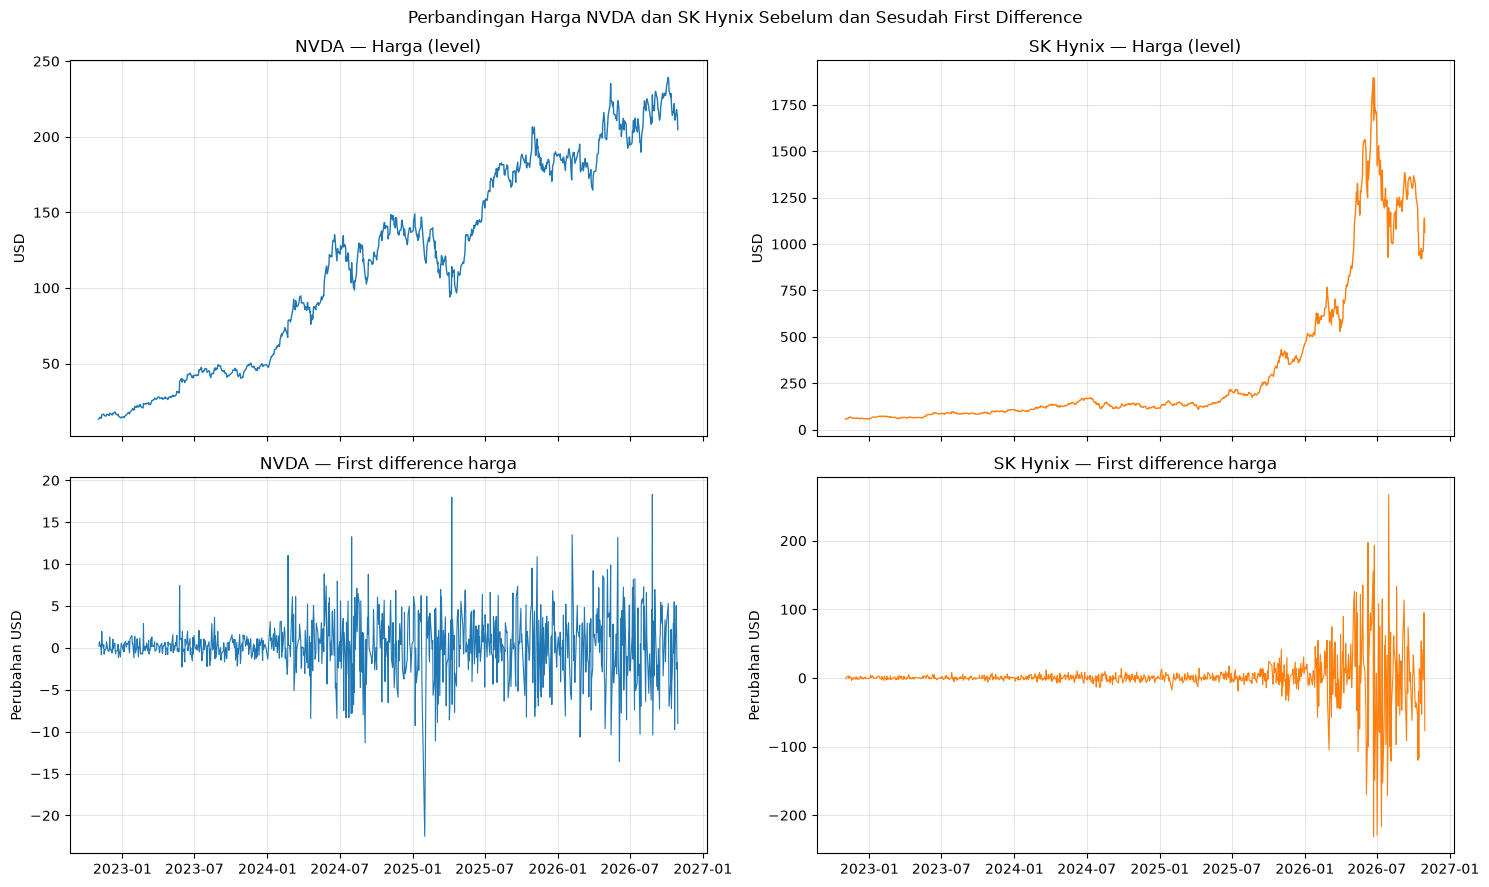

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)

for col, label, color in [
    ("NVDA_USD", "NVDA", "tab:blue"),
    ("SKHY_USD", "SK Hynix", "tab:orange"),
]:
    axes[0, 0 if col == "NVDA_USD" else 1].plot(
        df.index, df[col], color=color, linewidth=1
    )
    axes[0, 0 if col == "NVDA_USD" else 1].set_title(f"{label} — Harga (level)")
    axes[0, 0 if col == "NVDA_USD" else 1].set_ylabel("USD")

    axes[1, 0 if col == "NVDA_USD" else 1].plot(
        df.index, df[col].diff(), color=color, linewidth=0.8
    )
    axes[1, 0 if col == "NVDA_USD" else 1].set_title(
        f"{label} — First difference harga"
    )
    axes[1, 0 if col == "NVDA_USD" else 1].set_ylabel("Perubahan USD")

for ax in axes.flat:
    ax.grid(True, alpha=0.3)

fig.suptitle("Perbandingan Harga NVDA dan SK Hynix Sebelum dan Sesudah First Difference")
fig.tight_layout()
save_fig("phase2_prices_first_difference.png")
plt.show()

[Saved Figure] -> reports\figures\phase2_prices_log_first_difference.png


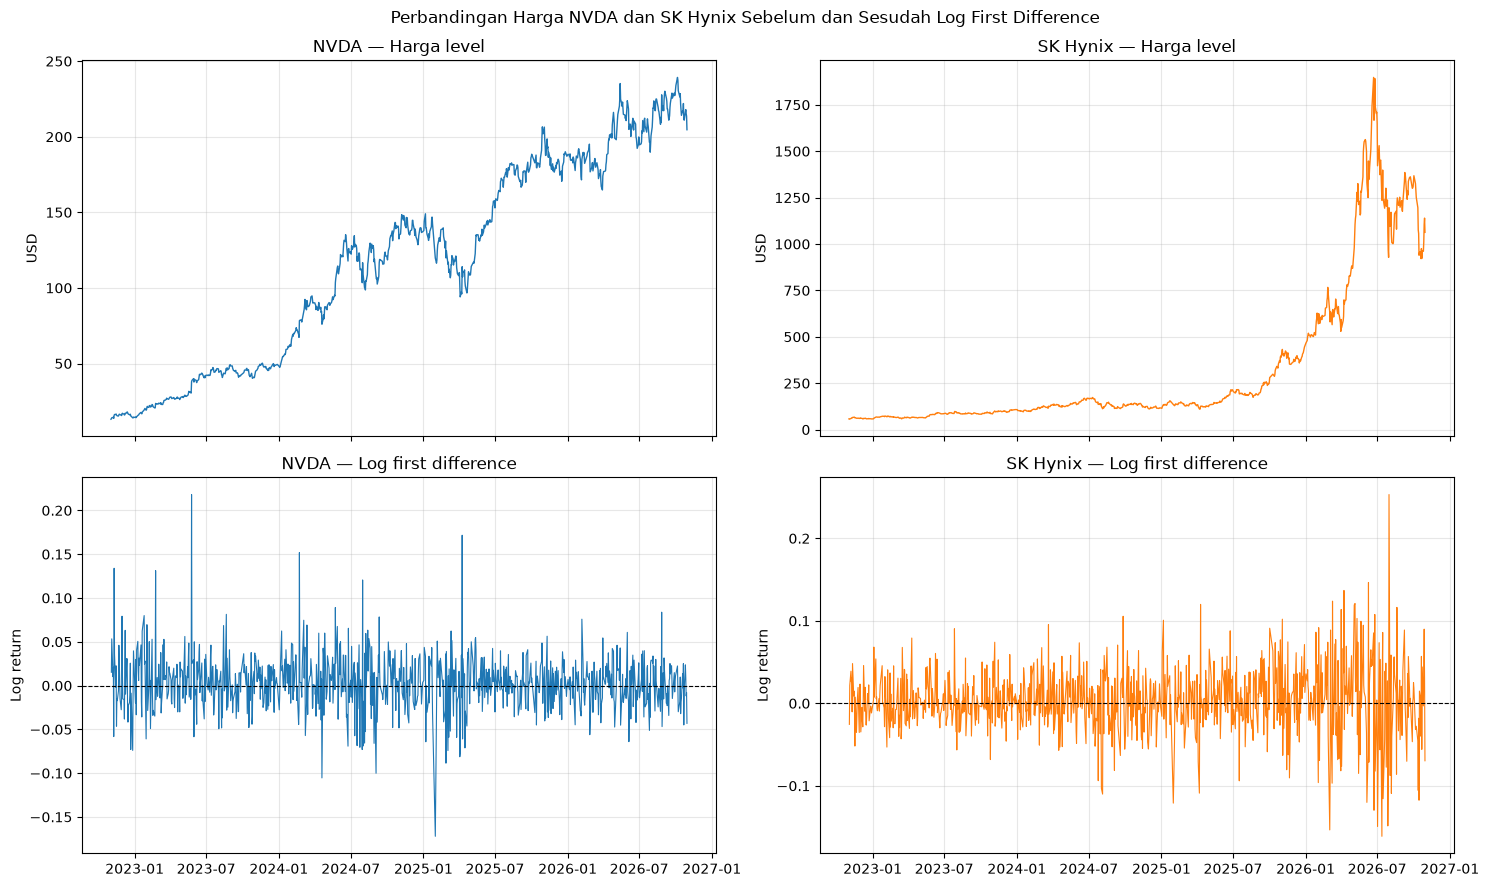

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)

assets = [
    ("NVDA_USD", "ln_NVDA", "NVDA", "tab:blue"),
    ("SKHY_USD", "ln_SKHY", "SK Hynix", "tab:orange"),
]

for col, log_col, label, color in assets:
    ax_level = axes[0, 0] if label == "NVDA" else axes[0, 1]
    ax_return = axes[1, 0] if label == "NVDA" else axes[1, 1]

    ax_level.plot(df.index, df[col], color=color, linewidth=1)
    ax_level.set_title(f"{label} — Harga level")
    ax_level.set_ylabel("USD")

    ax_return.plot(df.index, df[log_col].diff(), color=color, linewidth=0.8)
    ax_return.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax_return.set_title(f"{label} — Log first difference")
    ax_return.set_ylabel("Log return")

for ax in axes.flat:
    ax.grid(True, alpha=0.3)

fig.suptitle("Perbandingan Harga NVDA dan SK Hynix Sebelum dan Sesudah Log First Difference")
fig.tight_layout()
save_fig("phase2_prices_log_first_difference.png")
plt.show()

## Kesimpulan Uji Stasioneritas dan Derajat Integrasi

Berdasarkan uji **ADF, Phillips-Perron (PP), KPSS, dan Zivot-Andrews (ZA)** pada taraf signifikansi 5%, dapat disimpulkan:

1. **Harga logaritma NVDA dan SKHY**
    - Baik pada level maupun log level, seri NVDA dan SKHY umumnya tidak stasioner.
    - Pada first difference, terutama untuk log return, ADF, PP, dan Zivot-Andrews menolak hipotesis akar unit.
    - Uji KPSS juga mendukung stasioneritas pada transformasi first difference dengan spesifikasi tren.
    - Dengan demikian, **ln NVDA dan ln SKHY dipastikan terintegrasi I(1)**.

2. **VIX dan ln VIX**
    - Hasil uji level VIX bersifat tidak sepenuhnya konsisten antarspesifikasi:
      - PP mengindikasikan stasioneritas pada level.
      - KPSS mengindikasikan stasioneritas tanpa tren, tetapi tidak stasioner dengan tren.
      - Zivot-Andrews justru menolak akar unit pada level setelah memperhitungkan structural break.
    - Namun, seluruh uji pada **first difference** menunjukkan bahwa VIX dan ln VIX stasioner.
    - Oleh karena itu, secara defensif, perubahan VIX **q_t = Δln(VIX_t)** digunakan sebagai kontrol eksogen jangka pendek dalam VARX/VECMX.

3. **Implikasi model**
    - Dua seri harga saham merupakan variabel I(1), sehingga uji kointegrasi Johansen dan Engle-Granger diperlukan sebelum pemilihan model.
    - Apabila ditemukan rank kointegrasi r ≥ 1, digunakan VECMX.
    - Apabila rank kointegrasi r = 0, digunakan VARX pada log return NVDA dan SKHY.
    - Perubahan ln VIX akan tetap dimasukkan sebagai variabel eksogen pada kedua spesifikasi model.

## Langkah 4 — Uji Kointegrasi (Johansen & Engle-Granger)

**Tujuan.** Menguji keberadaan hubungan ekuilibrium jangka panjang yang stasioner antara harga logaritma NVDA dan SK Hynix. Uji dilakukan pada dua log harga saham:

$$
\mathbf{y}_t = \left[p_{NVDA,t},\, p_{SKHY,t}\right]', \qquad p_{i,t} = \ln(P_{i,t}).
$$

**Peran VIX.** VIX tidak dimasukkan ke dalam vektor kointegrasi karena berperan sebagai kontrol risiko/ketidakpastian global jangka pendek. Perubahan log VIX, $q_t = \Delta \ln(VIX_t)$, digunakan sebagai regressor eksogen pada VECMX/VARX. Uji rank Johansen standar tidak mengondisikan rank pada VIX; karena itu batasan ini dilaporkan dan dilengkapi analisis sensitivitas *conditional Johansen* dengan $q_t$ dikonsentrasi keluar dari sistem.

**Spesifikasi Johansen.** Trace dan maximum eigenvalue test dijalankan untuk:

- `det_order = 0`: konstanta dalam sistem (spesifikasi Case 3/unrestricted constant pada implementasi `statsmodels`);
- `det_order = -1`: tanpa deterministik (Case 1).

Lag diferensi mengikuti lag optimal dari kriteria informasi, lalu diuji sensitivitas pada beberapa lag di sekitar lag terpilih. Uji Engle-Granger dua langkah dijalankan pada dua arah regresi:

$$
p_{NVDA,t} = \theta_0 + \theta_1 p_{SKHY,t} + u_t,
\qquad
p_{SKHY,t} = \phi_0 + \phi_1 p_{NVDA,t} + v_t,
$$

kemudian stasioneritas residual diuji dengan ADF menggunakan nilai kritis Engle-Granger/MacKinnon.

**Aturan keputusan.**

- Jika rank Johansen $r \ge 1$ (atau Engle-Granger menolak $H_0$ tidak terkointegrasi), model jangka panjang yang dipakai adalah **VECMX**.
- Jika $r = 0$ dan Engle-Granger gagal menolak $H_0$, model yang dipakai adalah **VARX dalam first difference**.
- Jika kedua uji berbeda kesimpulan, Johansen trace test menjadi acuan utama dan hasil Engle-Granger dilaporkan sebagai konfirmasi/robustness.


In [8]:
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import coint_johansen, select_coint_rank
from statsmodels.tsa.stattools import coint, adfuller
import statsmodels.api as sm
import numpy as np

warnings.filterwarnings("ignore", category=np.exceptions.ComplexWarning)

# Data kointegrasi: dua log harga saham + kontrol eksogen perubahan log VIX.
coint_df = df[["ln_NVDA", "ln_SKHY", "d_ln_VIX"]].dropna().copy()
y_levels = coint_df[["ln_NVDA", "ln_SKHY"]]
q_vix = coint_df["d_ln_VIX"]

# ------------------------------------------------------------------
# Prasyarat Langkah 3: lag optimal VARX pada level dengan VIX eksogen
# ------------------------------------------------------------------
var_lag_model = VAR(y_levels, exog=q_vix)
lag_order = var_lag_model.select_order(maxlags=10, trend="c")

lag_table = pd.DataFrame({
    "Lag": np.arange(0, 11),
    "AIC": np.asarray(lag_order.aic, dtype=float),
    "BIC": np.asarray(lag_order.bic, dtype=float),
    "HQIC": np.asarray(lag_order.hqic, dtype=float),
    "FPE": np.asarray(lag_order.fpe, dtype=float),
})
lag_table["Kriteria Terpilih"] = ""
for criterion in ("aic", "bic", "hqic", "fpe"):
    selected_lag = int(lag_order.selected_orders[criterion])
    lag_table.loc[lag_table["Lag"] == selected_lag, "Kriteria Terpilih"] += criterion.upper() + " "
lag_table["Kriteria Terpilih"] = lag_table["Kriteria Terpilih"].str.strip()

display(lag_table)
save_table(lag_table, "phase4_lag_selection.csv", index=False)

p_opt = int(lag_order.selected_orders["aic"])
k_ar_diff_opt = max(p_opt - 1, 0)
print(f"Lag optimal AIC: p = {p_opt}; k_ar_diff Johansen = {k_ar_diff_opt}")
print(f"Rekomendasi BIC/HQIC/FPE: {int(lag_order.selected_orders['bic'])}, "
      f"{int(lag_order.selected_orders['hqic'])}, {int(lag_order.selected_orders['fpe'])}")


c:\Users\ahmdf\Documents\forecast-saham\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


,Lag,AIC,BIC,HQIC,FPE,Kriteria Terpilih
0,0,4.0,2.0,2.0,4.0,
1,1,4.0,2.0,2.0,4.0,
2,2,4.0,2.0,2.0,4.0,BIC HQIC
3,3,4.0,2.0,2.0,4.0,
4,4,4.0,2.0,2.0,4.0,AIC FPE
5,5,4.0,2.0,2.0,4.0,
6,6,4.0,2.0,2.0,4.0,
7,7,4.0,2.0,2.0,4.0,
8,8,4.0,2.0,2.0,4.0,
9,9,4.0,2.0,2.0,4.0,


[Saved Table]  -> reports\tables\phase4_lag_selection.csv
Lag optimal AIC: p = 4; k_ar_diff Johansen = 3
Rekomendasi BIC/HQIC/FPE: 2, 2, 4


In [9]:
# ------------------------------------------------------------------
# Uji Johansen: trace dan maximum eigenvalue
# ------------------------------------------------------------------
def infer_johansen_rank(test_stats, crit_vals, signif_col=1):
    rank = 0
    for i, stat in enumerate(test_stats):
        if stat > crit_vals[i, signif_col]:
            rank = i + 1
        else:
            break
    return rank


johansen_specs = [
    ("Case 3: konstanta (det_order=0)", 0),
    ("Case 1: tanpa deterministik (det_order=-1)", -1),
]
johansen_rows = []
johansen_primary = None

for spec_name, det_order in johansen_specs:
    joh = coint_johansen(y_levels, det_order=det_order, k_ar_diff=k_ar_diff_opt)
    if det_order == 0:
        johansen_primary = joh

    for i in range(y_levels.shape[1]):
        for test_name, stats, crit_vals in (
            ("Trace", joh.trace_stat, joh.trace_stat_crit_vals),
            ("Max eigenvalue", joh.max_eig_stat, joh.max_eig_stat_crit_vals),
        ):
            johansen_rows.append({
                "Spesifikasi": spec_name,
                "Uji": test_name,
                "H0": f"r <= {i}",
                "Statistic": stats[i],
                "CV 90%": crit_vals[i, 0],
                "CV 95%": crit_vals[i, 1],
                "CV 99%": crit_vals[i, 2],
                "Tolak H0 (5%)": "Ya" if stats[i] > crit_vals[i, 1] else "Tidak",
            })

johansen_table = pd.DataFrame(johansen_rows)
display(johansen_table)
save_table(johansen_table, "phase4_johansen_results.csv", index=False)

joh_trace_rank = infer_johansen_rank(
    johansen_primary.trace_stat, johansen_primary.trace_stat_crit_vals, signif_col=1
)
joh_maxeig_rank = infer_johansen_rank(
    johansen_primary.max_eig_stat, johansen_primary.max_eig_stat_crit_vals, signif_col=1
)
joh_trace_rank_90 = infer_johansen_rank(
    johansen_primary.trace_stat, johansen_primary.trace_stat_crit_vals, signif_col=0
)
joh_rank_select = select_coint_rank(
    y_levels, det_order=0, k_ar_diff=k_ar_diff_opt, method="trace", signif=0.05
).rank

print(f"Rank Johansen (trace, 5%)          : {joh_trace_rank}")
print(f"Rank Johansen (max eigenvalue, 5%) : {joh_maxeig_rank}")
print(f"Rank Johansen (trace, 10%)         : {joh_trace_rank_90}")
print(f"Konfirmasi select_coint_rank (5%)  : {joh_rank_select}")

# Sensitivitas jumlah lag diferensi (termasuk lag yang lebih kecil/lebih besar).
johansen_lag_rows = []
for k_diff in range(0, p_opt + 1):
    joh_lag = coint_johansen(y_levels, det_order=0, k_ar_diff=k_diff)
    johansen_lag_rows.append({
        "k_ar_diff": k_diff,
        "VAR lag (p)": k_diff + 1,
        "Trace r=0": joh_lag.trace_stat[0],
        "CV 95% r=0": joh_lag.trace_stat_crit_vals[0, 1],
        "Max eig r=0": joh_lag.max_eig_stat[0],
        "CV 95% max eig r=0": joh_lag.max_eig_stat_crit_vals[0, 1],
        "Rank trace (5%)": infer_johansen_rank(
            joh_lag.trace_stat, joh_lag.trace_stat_crit_vals, signif_col=1
        ),
        "Rank max eig (5%)": infer_johansen_rank(
            joh_lag.max_eig_stat, joh_lag.max_eig_stat_crit_vals, signif_col=1
        ),
    })

johansen_lag_table = pd.DataFrame(johansen_lag_rows)
display(johansen_lag_table)
save_table(johansen_lag_table, "phase4_johansen_lag_sensitivity.csv", index=False)


,Spesifikasi,Uji,H0,Statistic,CV 90%,CV 95%,CV 99%,Tolak H0 (5%)
0,Case 3: konstanta (det_order=0),Trace,r <= 0,11.614431,13.4294,15.4943,19.9349,Tidak
1,Case 3: konstanta (det_order=0),Max eigenvalue,r <= 0,11.398238,12.2971,14.2639,18.5200,Tidak
2,Case 3: konstanta (det_order=0),Trace,r <= 1,0.216194,2.7055,3.8415,6.6349,Tidak
3,Case 3: konstanta (det_order=0),Max eigenvalue,r <= 1,0.216194,2.7055,3.8415,6.6349,Tidak
4,Case 1: tanpa deterministik (det_order=-1),Trace,r <= 0,10.267238,10.4741,12.3212,16.3640,Tidak
5,Case 1: tanpa deterministik (det_order=-1),Max eigenvalue,r <= 0,8.705033,9.4748,11.2246,15.0923,Tidak
6,Case 1: tanpa deterministik (det_order=-1),Trace,r <= 1,1.562205,2.9762,4.1296,6.9406,Tidak
7,Case 1: tanpa deterministik (det_order=-1),Max eigenvalue,r <= 1,1.562205,2.9762,4.1296,6.9406,Tidak


[Saved Table]  -> reports\tables\phase4_johansen_results.csv
Rank Johansen (trace, 5%)          : 0
Rank Johansen (max eigenvalue, 5%) : 0
Rank Johansen (trace, 10%)         : 0
Konfirmasi select_coint_rank (5%)  : 0


,k_ar_diff,VAR lag (p),Trace r=0,CV 95% r=0,Max eig r=0,CV 95% max eig r=0,Rank trace (5%),Rank max eig (5%)
0,0,1,6.383155,15.4943,6.358765,14.2639,0,0
1,1,2,11.588252,15.4943,11.469642,14.2639,0,0
2,2,3,10.494553,15.4943,10.391318,14.2639,0,0
3,3,4,11.614431,15.4943,11.398238,14.2639,0,0
4,4,5,11.591761,15.4943,11.310404,14.2639,0,0


[Saved Table]  -> reports\tables\phase4_johansen_lag_sensitivity.csv


In [10]:
# ------------------------------------------------------------------
# Sensitivitas: conditional Johansen dengan q_t = Delta ln(VIX) eksogen
# ------------------------------------------------------------------
def johansen_with_exog(y, exog, k_ar_diff, det_order=0):

    y = np.asarray(y, dtype=float)
    exog = np.asarray(exog, dtype=float).reshape(len(y), -1)

    dy = np.diff(y, axis=0)
    levels_lag = y[:-1]
    total = len(dy)

    if k_ar_diff > 0:
        lagged_dy = np.column_stack([
            dy[k_ar_diff - i: total - i] for i in range(1, k_ar_diff + 1)
        ])
    else:
        lagged_dy = np.empty((total, 0))

    dy_eff = dy[k_ar_diff:]
    levels_eff = levels_lag[k_ar_diff:]
    exog_eff = exog[1:][k_ar_diff:]

    regressors = [exog_eff, lagged_dy]
    if det_order == 0:
        regressors.insert(0, np.ones((len(dy_eff), 1)))
    X = np.column_stack(regressors)

    def residualize(values):
        return values - X @ np.linalg.pinv(X) @ values

    r0 = residualize(dy_eff)
    r1 = residualize(levels_eff)
    n_eff = len(r0)

    s00 = r0.T @ r0 / n_eff
    s01 = r0.T @ r1 / n_eff
    s10 = r1.T @ r0 / n_eff
    s11 = r1.T @ r1 / n_eff

    eigvals = np.linalg.eigvals(
        np.linalg.solve(s11, s10 @ np.linalg.solve(s00, s01))
    )
    eigvals = np.sort(np.real(eigvals))[::-1]
    eigvals = np.clip(eigvals, 0.0, 1 - 1e-12)

    trace_stat = -n_eff * np.cumsum(np.log(1 - eigvals)[::-1])[::-1]
    max_eig_stat = -n_eff * np.log(1 - eigvals)
    return {
        "eig": eigvals,
        "trace_stat": trace_stat,
        "max_eig_stat": max_eig_stat,
        "nobs": n_eff,
    }


joh_exog = johansen_with_exog(
    y_levels, q_vix, k_ar_diff=k_ar_diff_opt, det_order=0
)
joh_exog_rank = infer_johansen_rank(
    joh_exog["trace_stat"], johansen_primary.trace_stat_crit_vals, signif_col=1
)

# Nilai kritis memakai tabel bivariat standar; lihat catatan metodologis.
exog_rows = []
for i in range(y_levels.shape[1]):
    exog_rows.append({
        "H0": f"r <= {i}",
        "Trace Statistic": joh_exog["trace_stat"][i],
        "CV 90%": johansen_primary.trace_stat_crit_vals[i, 0],
        "CV 95%": johansen_primary.trace_stat_crit_vals[i, 1],
        "CV 99%": johansen_primary.trace_stat_crit_vals[i, 2],
        "Tolak H0 (5%)": (
            "Ya" if joh_exog["trace_stat"][i] > johansen_primary.trace_stat_crit_vals[i, 1]
            else "Tidak"
        ),
    })

joh_exog_table = pd.DataFrame(exog_rows)
display(joh_exog_table)
save_table(joh_exog_table, "phase4_johansen_exog_vix_sensitivity.csv", index=False)

print(f"Conditional Johansen (q_t eksogen), rank trace 5%: {joh_exog_rank}")
print(f"Jumlah observasi efektif: {joh_exog['nobs']}")


,H0,Trace Statistic,CV 90%,CV 95%,CV 99%,Tolak H0 (5%)
0,r <= 0,11.271305,13.4294,15.4943,19.9349,Tidak
1,r <= 1,0.230132,2.7055,3.8415,6.6349,Tidak


[Saved Table]  -> reports\tables\phase4_johansen_exog_vix_sensitivity.csv
Conditional Johansen (q_t eksogen), rank trace 5%: 0
Jumlah observasi efektif: 938


In [11]:
# ------------------------------------------------------------------
# Uji Engle-Granger dua langkah (dua arah regresi)
# ------------------------------------------------------------------
eg_rows = []
eg_residuals = {}
eg_models = {}

for dependent, independent, direction in (
    ("ln_NVDA", "ln_SKHY", "NVDA ~ SKHY"),
    ("ln_SKHY", "ln_NVDA", "SKHY ~ NVDA"),
):
    y0 = coint_df[dependent]
    y1 = coint_df[independent]

    ols_model = sm.OLS(y0, sm.add_constant(y1)).fit()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)
        adf_stat, adf_pvalue, adf_lag, adf_nobs, adf_crit, _ = adfuller(
            ols_model.resid, autolag="AIC"
        )

    eg_stat, eg_pvalue, eg_crit = coint(y0, y1, trend="c", autolag="AIC")

    eg_models[direction] = ols_model
    eg_residuals[direction] = ols_model.resid

    eg_rows.append({
        "Arah Regresi": direction,
        "Konstanta": ols_model.params["const"],
        "Slope theta": ols_model.params[independent],
        "R-squared": ols_model.rsquared,
        "ADF Residual": adf_stat,
        "Lag ADF": adf_lag,
        "P-Value ADF (indikatif)": adf_pvalue,
        "EG Statistic": eg_stat,
        "P-Value EG": eg_pvalue,
        "CV EG 1%": eg_crit[0],
        "CV EG 5%": eg_crit[1],
        "CV EG 10%": eg_crit[2],
        "Kesimpulan (5%)": (
            "Tolak H0: terkointegrasi"
            if eg_pvalue < 0.05
            else "Gagal tolak H0: tidak terkointegrasi"
        ),
    })

eg_table = pd.DataFrame(eg_rows)
display(eg_table)
save_table(eg_table, "phase4_engle_granger_results.csv", index=False)


,Arah Regresi,Konstanta,Slope theta,R-squared,ADF Residual,Lag ADF,P-Value ADF (indikatif),EG Statistic,P-Value EG,CV EG 1%,CV EG 5%,CV EG 10%,Kesimpulan (5%)
0,NVDA ~ SKHY,1.078073,0.657618,0.626795,-2.311948,1,0.168144,-2.309081,0.369030,-3.908116,-3.342631,-3.04896,Gagal tolak H0: tidak terkointegrasi
1,SKHY ~ NVDA,0.924386,0.953129,0.626795,-0.692511,15,0.848680,-0.701409,0.946486,-3.908116,-3.342631,-3.04896,Gagal tolak H0: tidak terkointegrasi


[Saved Table]  -> reports\tables\phase4_engle_granger_results.csv


In [12]:
# ------------------------------------------------------------------
# Keputusan model: VECMX vs VARX first difference
# ------------------------------------------------------------------
eg_coint = bool((eg_table["P-Value EG"] < 0.05).any())
joh_coint = joh_trace_rank >= 1

if joh_coint:
    model_choice = "VECMX"
    next_phase = "5A — Estimasi VECMX"
    decision_note = "Rank Johansen >= 1: hubungan ekuilibrium jangka panjang didukung."
elif eg_coint:
    model_choice = "VECMX (dengan catatan robustness)"
    next_phase = "5A — Estimasi VECMX, disertai sensitivitas"
    decision_note = "Johansen tidak menolak r=0, tetapi Engle-Granger menolak H0. Prioritaskan Johansen dan laporkan konflik."
else:
    model_choice = "VARX dalam first difference"
    next_phase = "5B — Estimasi VARX first difference"
    decision_note = "Johansen dan Engle-Granger sama-sama tidak menemukan kointegrasi."

decision_table = pd.DataFrame({
    "Komponen": [
        "Rank Johansen (trace, 5%)",
        "Rank Johansen (max eigenvalue, 5%)",
        "Rank Johansen (trace, 10%)",
        "Conditional Johansen dengan q_t (5%)",
        "Engle-Granger: jumlah arah yang menolak H0",
        "Keputusan model",
        "Langkah berikutnya",
    ],
    "Hasil": [
        joh_trace_rank,
        joh_maxeig_rank,
        joh_trace_rank_90,
        joh_exog_rank,
        int((eg_table["P-Value EG"] < 0.05).sum()),
        model_choice,
        next_phase,
    ],
})

display(decision_table)
save_table(decision_table, "phase4_cointegration_decision.csv", index=False)
print(decision_note)


,Komponen,Hasil
0,"Rank Johansen (trace, 5%)",0
1,"Rank Johansen (max eigenvalue, 5%)",0
2,"Rank Johansen (trace, 10%)",0
3,Conditional Johansen dengan q_t (5%),0
4,Engle-Granger: jumlah arah yang menolak H0,0
5,Keputusan model,VARX dalam first difference
6,Langkah berikutnya,5B — Estimasi VARX first difference


[Saved Table]  -> reports\tables\phase4_cointegration_decision.csv
Johansen dan Engle-Granger sama-sama tidak menemukan kointegrasi.


[Saved Figure] -> reports\figures\phase4_engle_granger_residuals.png


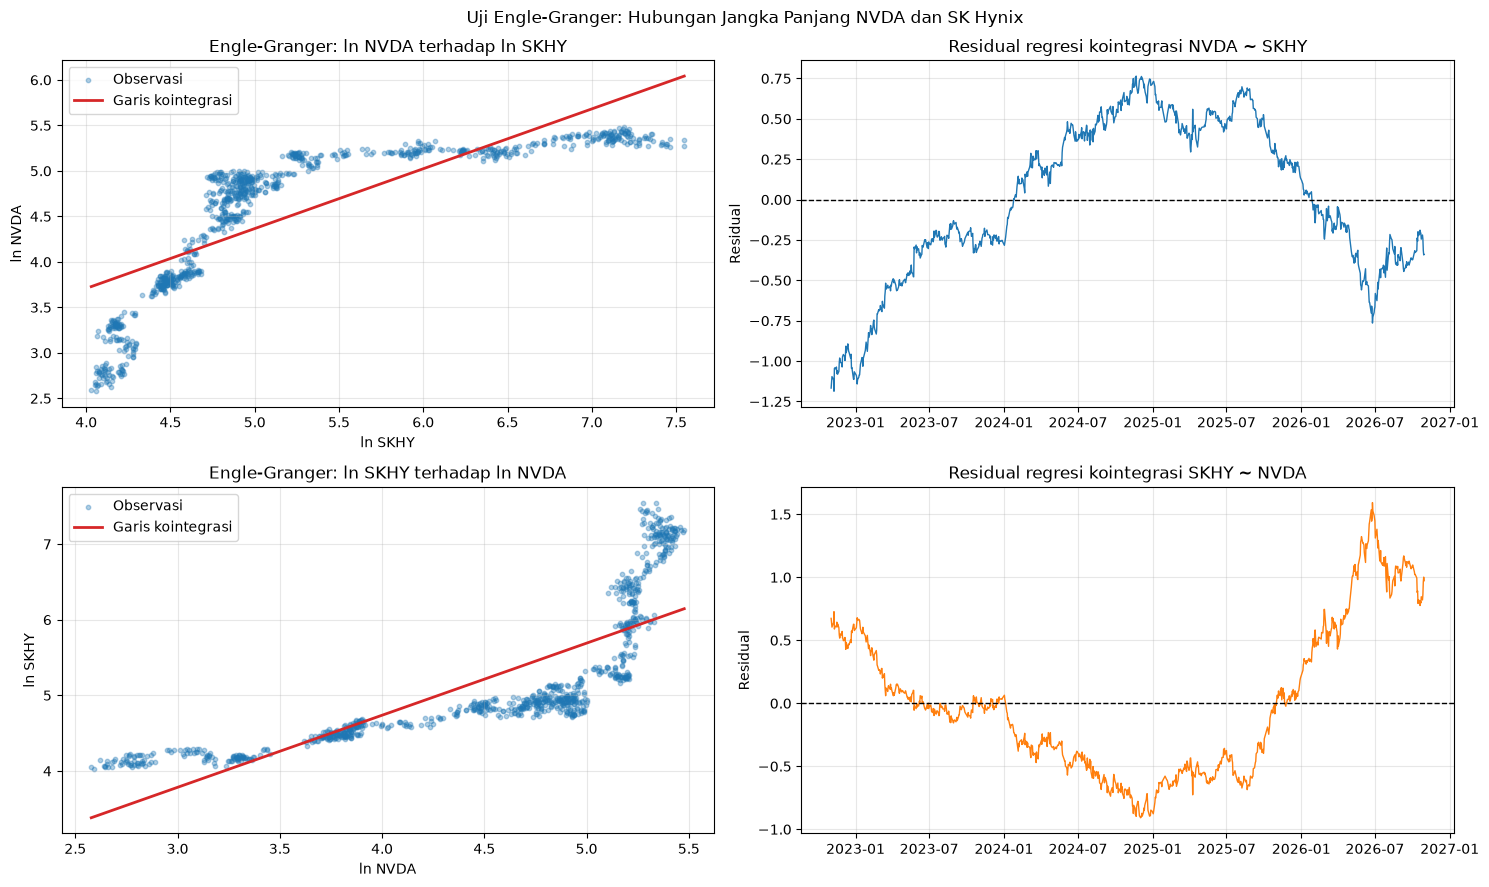

[Saved Figure] -> reports\figures\phase4_johansen_trace.png


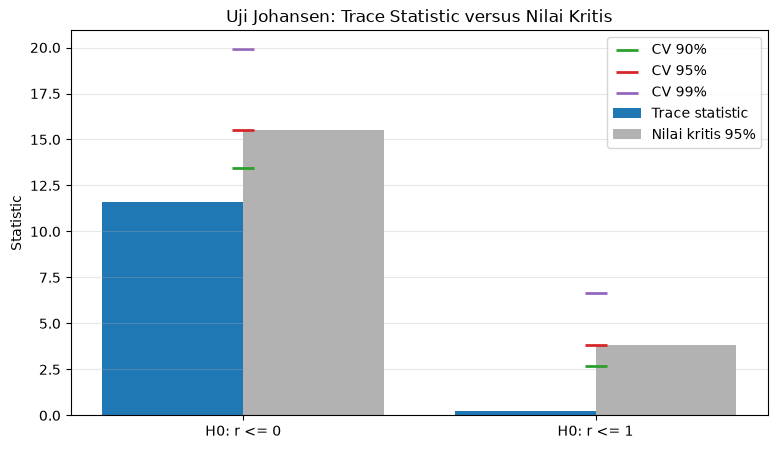

In [13]:
# ------------------------------------------------------------------
# Visualisasi: Engle-Granger dan trace test Johansen
# ------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# Sebaran log harga + garis regresi kointegrasi (NVDA ~ SKHY).
axes[0, 0].scatter(coint_df["ln_SKHY"], coint_df["ln_NVDA"], s=10, alpha=0.35, label="Observasi")
x_grid = np.linspace(coint_df["ln_SKHY"].min(), coint_df["ln_SKHY"].max(), 100)
ols_nvda = eg_models["NVDA ~ SKHY"]
axes[0, 0].plot(
    x_grid,
    ols_nvda.params["const"] + ols_nvda.params["ln_SKHY"] * x_grid,
    color="tab:red",
    linewidth=2,
    label="Garis kointegrasi",
)
axes[0, 0].set_title("Engle-Granger: ln NVDA terhadap ln SKHY")
axes[0, 0].set_xlabel("ln SKHY")
axes[0, 0].set_ylabel("ln NVDA")
axes[0, 0].legend()

# Residual NVDA ~ SKHY.
axes[0, 1].plot(eg_residuals["NVDA ~ SKHY"], color="tab:blue", linewidth=1)
axes[0, 1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0, 1].set_title("Residual regresi kointegrasi NVDA ~ SKHY")
axes[0, 1].set_ylabel("Residual")

# Sebaran log harga + garis regresi kointegrasi (SKHY ~ NVDA).
axes[1, 0].scatter(coint_df["ln_NVDA"], coint_df["ln_SKHY"], s=10, alpha=0.35, label="Observasi")
x_grid_rev = np.linspace(coint_df["ln_NVDA"].min(), coint_df["ln_NVDA"].max(), 100)
ols_skhy = eg_models["SKHY ~ NVDA"]
axes[1, 0].plot(
    x_grid_rev,
    ols_skhy.params["const"] + ols_skhy.params["ln_NVDA"] * x_grid_rev,
    color="tab:red",
    linewidth=2,
    label="Garis kointegrasi",
)
axes[1, 0].set_title("Engle-Granger: ln SKHY terhadap ln NVDA")
axes[1, 0].set_xlabel("ln NVDA")
axes[1, 0].set_ylabel("ln SKHY")
axes[1, 0].legend()

# Residual SKHY ~ NVDA.
axes[1, 1].plot(eg_residuals["SKHY ~ NVDA"], color="tab:orange", linewidth=1)
axes[1, 1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1, 1].set_title("Residual regresi kointegrasi SKHY ~ NVDA")
axes[1, 1].set_ylabel("Residual")

for ax in axes.flat:
    ax.grid(True, alpha=0.3)

fig.suptitle("Uji Engle-Granger: Hubungan Jangka Panjang NVDA dan SK Hynix")
fig.tight_layout()
save_fig("phase4_engle_granger_residuals.png")
plt.show()

# Trace statistic versus nilai kritis.
fig, ax = plt.subplots(figsize=(9, 5))
hypotheses = [f"H0: r <= {i}" for i in range(y_levels.shape[1])]
positions = np.arange(len(hypotheses))

ax.bar(
    positions - 0.2,
    johansen_primary.trace_stat,
    width=0.4,
    color="tab:blue",
    label="Trace statistic",
)
ax.bar(
    positions + 0.2,
    johansen_primary.trace_stat_crit_vals[:, 1],
    width=0.4,
    color="tab:gray",
    alpha=0.6,
    label="Nilai kritis 95%",
)
for level, column, marker_color in (
    ("90%", 0, "tab:green"),
    ("95%", 1, "tab:red"),
    ("99%", 2, "tab:purple"),
):
    ax.scatter(
        positions,
        johansen_primary.trace_stat_crit_vals[:, column],
        marker="_",
        s=250,
        linewidths=2,
        color=marker_color,
        label=f"CV {level}",
    )
ax.set_xticks(positions)
ax.set_xticklabels(hypotheses)
ax.set_ylabel("Statistic")
ax.set_title("Uji Johansen: Trace Statistic versus Nilai Kritis")
ax.legend(loc="upper right")
ax.grid(True, axis="y", alpha=0.3)
save_fig("phase4_johansen_trace.png")
plt.show()


## Kesimpulan Langkah 4

1. **Lag optimal.** AIC memilih $p = 4$ ($k\_ar\_diff = 3$) pada sistem dua log harga dengan perubahan log VIX sebagai eksogen; BIC dan HQIC memilih $p = 2$. Spesifikasi utama menggunakan lag AIC, sedangkan lag alternatif $k\_ar\_diff = 0,\ldots,4$ dilaporkan pada tabel sensitivitas.

2. **Uji Johansen.** Pada taraf 5%, trace statistic untuk $H_0: r = 0$ sebesar **11.614** dengan nilai kritis 95% **15.494**; maximum eigenvalue statistic sebesar **11.398** dengan nilai kritis 95% **14.264**. Kedua uji gagal menolak $r = 0$. Spesifikasi tanpa deterministik (`det_order=-1`) dan seluruh lag sensitivitas juga menghasilkan rank 0. Conditional Johansen dengan $q_t = \Delta\ln(VIX)$ sebagai regressor eksogen menghasilkan trace statistic **11.271** (nilai kritis indikatif 95%: 15.494), sehingga kesimpulan rank 0 tetap konsisten.

3. **Uji Engle-Granger.** Kedua arah regresi gagal menolak hipotesis nol tidak terkointegrasi:
   - NVDA $\sim$ SKHY: EG statistic **-2.309**, p-value **0.369**;
   - SKHY $\sim$ NVDA: EG statistic **-0.701**, p-value **0.946**.

4. **Keputusan model.** Tidak ada bukti ekuilibrium jangka panjang yang stasioner antara log harga NVDA dan SK Hynix. Langkah berikutnya adalah **VARX dalam log return** (Langkah 5B) dengan $q_t = \Delta\ln(VIX_t)$ sebagai kontrol eksogen jangka pendek. Hasil ini juga konsisten dengan temuan awal pada `AGENTS.md` yang mencatat trace statistic berada di sekitar ambang batas; perbedaan angka disebabkan oleh sampel, lag, dan spesifikasi deterministik yang dipakai.

> **Batasan.** Uji rank Johansen standar tidak mengondisikan rank pada VIX. Analisis conditional Johansen di atas adalah sensitivitas, bukan uji formal dengan nilai kritis yang disesuaikan untuk regressor eksogen. VIX tetap diperlakukan sebagai kontrol jangka pendek, bukan komponen vektor kointegrasi.
